In [1]:
%pip install numpy matplotlib opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\shash\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


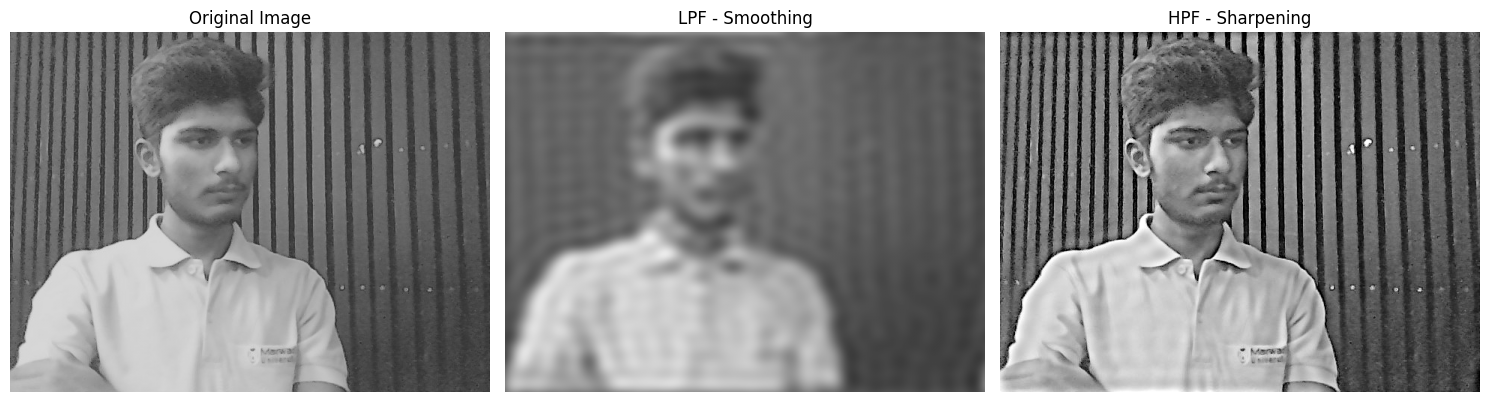

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the image in grayscale
img = cv2.imread(r"c:\Users\shash\Documents\SHASHIDAHR_18\Photos\hello_51.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "Image not found. Keep image.jpg in the notebook folder."
    )

# 2. Apply 2D Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))

# 3. Create frequency distance matrix
M, N = img.shape
u, v = np.meshgrid(
    np.arange(N) - N // 2,
    np.arange(M) - M // 2
)
D = np.sqrt(u**2 + v**2)

# 4. Create Low-Pass and High-Pass Filters
cutoff = 30
LPF = (D < cutoff)
HPF = (D >= cutoff)

# 5. Apply Low-Pass Filter for smoothing
smooth_complex = np.fft.ifft2(
    np.fft.ifftshift(F * LPF)
)
smooth = np.clip(np.abs(smooth_complex), 0, 255).astype(np.uint8)

# 6. Apply High-Pass Filter for sharpening
high_complex = np.fft.ifft2(
    np.fft.ifftshift(F * HPF)
)
high_pass = np.real(high_complex)

sharp = np.clip(
    img.astype(float) + high_pass, 0, 255).astype(np.uint8)

# 7. Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap="gray", vmin=0, vmax=255)
plt.title("LPF - Smoothing")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap="gray", vmin=0, vmax=255)
plt.title("HPF - Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()
